# Gauge Gap Prioritization

This notebook scores and ranks ungauged HUC-10 watersheds using four risk/exposure indicators:

1. **Disaster count** — area-weighted allocation of disaster event counts
2. **Insurance claim amount** — sum of NFIP claim totals from points within each HUC-10
3. **Road length** — total road network length (km) intersecting each HUC-10
4. **Population** — area-weighted allocation of population

Indicators are normalized using IQR-clipped min-max scaling computed over ungauged candidates only, then combined into an equal-weight composite priority score.

**Inputs:** A single GeoPackage (`data/prioritization.gpkg`) containing HUC-10, ungauged HUC-10, disasters, claims, roads, and population layers.  
**Outputs:** A GeoPackage and CSVs written to `prioritization_out/`.

**Requirements:** `numpy`, `pandas`, `geopandas`, `matplotlib`

## 1. Imports

In [1]:
from __future__ import annotations

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import BoundaryNorm
from matplotlib.cm import ScalarMappable

## 2. Configuration

All file paths, layer names, column mappings, and CRS settings are centralized here. Edit this block before running the notebook.

In [2]:
INPUT_GPKG = "prioritization.gpkg"

LAYER_NAMES = {
    "huc10":          "huc10",
    "ungauged_huc10": "ungaugedhuc10",
    "disaster":       "disasters",
    "claim":          "claim",
    "road":           "roads",
    "population":     "population",
}

COLUMN_NAMES = {
    "huc10_id":       "huc10",
    "disaster_count": "Count",
    "claim_amount":   "total_amount",
    "population":     "Population",
}

METRIC_CRS = "EPSG:5070"

OUTPUT_DIR          = Path("prioritization_out")
OUTPUT_GPKG         = OUTPUT_DIR / "prioritization_outputs.gpkg"
OUTPUT_CSV_ALL      = OUTPUT_DIR / "prioritization_outputs_all.csv"
OUTPUT_CSV_UNGAUGED = OUTPUT_DIR / "prioritization_outputs_ungauged.csv"

## 3. Utility Functions

Three spatial aggregation helpers used to compute indicator values per HUC-10:

- `area_weighted_overlay_sum` — allocates polygon values to target polygons proportionally by intersection area
- `point_sum_within_polygons` — sums point-level values falling within each polygon
- `line_length_within_polygons_km` — computes total clipped line length (km) within each polygon

A normalization helper `normalize_indicators` applies IQR-clipped min-max scaling using only ungauged candidate rows to compute the scaling bounds, then applies those bounds to all rows.

In [3]:
def _coerce_numeric(series: pd.Series) -> pd.Series:
    """Coerce a Series to float, replacing non-parseable values with 0."""
    return pd.to_numeric(series, errors="coerce").fillna(0.0)


def area_weighted_overlay_sum(
    target_gdf: gpd.GeoDataFrame,
    source_gdf: gpd.GeoDataFrame,
    target_id_col: str,
    source_value_col: str,
) -> pd.Series:
    """
    Allocate polygon-level values to target polygons by overlap fraction.

    Each source polygon contributes proportionally:
        contribution = source_value * (intersection_area / source_area)

    Returns a Series indexed by target_id_col.
    """
    src = source_gdf[[source_value_col, "geometry"]].copy()
    src[source_value_col] = _coerce_numeric(src[source_value_col])
    src["src_area"] = src.geometry.area
    src = src[src["src_area"] > 0].copy()

    intersection = gpd.overlay(
        target_gdf[[target_id_col, "geometry"]],
        src,
        how="intersection",
        keep_geom_type=False,
    )

    if intersection.empty:
        result = pd.Series(0.0, index=target_gdf[target_id_col].values)
        result.index.name = target_id_col
        return result

    intersection["int_area"] = intersection.geometry.area
    intersection["frac"]     = intersection["int_area"] / intersection["src_area"]
    intersection["alloc"]    = intersection[source_value_col] * intersection["frac"]

    result = intersection.groupby(target_id_col)["alloc"].sum()
    result = result.reindex(target_gdf[target_id_col].values, fill_value=0.0)
    result.index.name = target_id_col
    return result


def point_sum_within_polygons(
    polygons_gdf: gpd.GeoDataFrame,
    points_gdf: gpd.GeoDataFrame,
    poly_id_col: str,
    value_col: str,
) -> pd.Series:
    """
    Sum point-level values for all points falling within each polygon.

    Returns a Series indexed by poly_id_col.
    """
    pts = points_gdf[[value_col, "geometry"]].copy()
    pts[value_col] = _coerce_numeric(pts[value_col])

    joined = gpd.sjoin(pts, polygons_gdf[[poly_id_col, "geometry"]], predicate="within", how="inner")

    if joined.empty:
        result = pd.Series(0.0, index=polygons_gdf[poly_id_col].values)
        result.index.name = poly_id_col
        return result

    result = joined.groupby(poly_id_col)[value_col].sum()
    result = result.reindex(polygons_gdf[poly_id_col].values, fill_value=0.0)
    result.index.name = poly_id_col
    return result


def line_length_within_polygons_km(
    polygons_gdf: gpd.GeoDataFrame,
    lines_gdf: gpd.GeoDataFrame,
    poly_id_col: str,
) -> pd.Series:
    """
    Compute the total length (km) of lines clipped to each polygon.

    Polygon IDs are zero-padded to 10 characters for consistent joining.
    Empty or null geometries in the lines layer are dropped before overlay.
    Returns a Series indexed by poly_id_col.
    """
    polys = polygons_gdf[[poly_id_col, "geometry"]].copy()
    polys[poly_id_col] = polys[poly_id_col].astype(str).str.strip().str.zfill(10)

    lines = lines_gdf[["geometry"]].copy()
    lines = lines[lines.geometry.notna() & (~lines.geometry.is_empty)].copy()

    intersection = gpd.overlay(
        polys,
        lines,
        how="intersection",
        keep_geom_type=False,
    )

    if intersection.empty:
        result = pd.Series(0.0, index=polys[poly_id_col].values)
        result.index.name = poly_id_col
        return result

    intersection[poly_id_col] = intersection[poly_id_col].astype(str).str.strip().str.zfill(10)
    intersection["seg_len_m"] = intersection.geometry.length

    result = intersection.groupby(poly_id_col)["seg_len_m"].sum()
    result = result.reindex(polys[poly_id_col].values, fill_value=0.0)
    result.index.name = poly_id_col
    return result / 1000.0


def normalize_indicators(
    df: pd.DataFrame,
    indicator_cols: list[str],
    candidate_mask: pd.Series,
) -> pd.DataFrame:
    """
    Normalize indicator columns using IQR-clipped min-max scaling.

    Scaling bounds (clip range, min, max) are derived from candidate rows only,
    then applied uniformly to all rows. Adds `<col>_norm` columns to the returned
    DataFrame.
    """
    out = df.copy()
    for col in indicator_cols:
        candidate_values = out.loc[candidate_mask, col].astype(float)

        q1  = candidate_values.quantile(0.25)
        q3  = candidate_values.quantile(0.75)
        iqr = q3 - q1
        clip_lo = q1 - 1.5 * iqr
        clip_hi = q3 + 1.5 * iqr

        clipped      = out[col].astype(float).clip(clip_lo, clip_hi)
        scale_min    = clipped.loc[candidate_mask].min()
        scale_max    = clipped.loc[candidate_mask].max()

        if np.isclose(scale_max - scale_min, 0.0):
            out[col + "_norm"] = 0.0
        else:
            out[col + "_norm"] = (clipped - scale_min) / (scale_max - scale_min)

    return out

## 4. Load and Validate Layers

All layers are read from the input GeoPackage, HUC IDs are standardized to zero-padded 10-character strings, and all layers are reprojected to the metric CRS (`EPSG:5070`) for accurate area and length computations.

The HUC-10 ID column is validated to exist in both the full HUC-10 layer and the ungauged candidates layer before proceeding.

In [4]:
huc10      = gpd.read_file(INPUT_GPKG, layer=LAYER_NAMES["huc10"])
ungauged   = gpd.read_file(INPUT_GPKG, layer=LAYER_NAMES["ungauged_huc10"])
disaster   = gpd.read_file(INPUT_GPKG, layer=LAYER_NAMES["disaster"])
claim      = gpd.read_file(INPUT_GPKG, layer=LAYER_NAMES["claim"])
road       = gpd.read_file(INPUT_GPKG, layer=LAYER_NAMES["road"])
population = gpd.read_file(INPUT_GPKG, layer=LAYER_NAMES["population"])

huc_id_col = COLUMN_NAMES["huc10_id"]

if huc_id_col not in huc10.columns:
    raise ValueError(
        f"HUC-10 ID column '{huc_id_col}' not found in layer '{LAYER_NAMES['huc10']}'. "
        "Check COLUMN_NAMES['huc10_id'] in CONFIG."
    )
if huc_id_col not in ungauged.columns:
    raise ValueError(
        f"HUC-10 ID column '{huc_id_col}' not found in layer '{LAYER_NAMES['ungauged_huc10']}'. "
        "The ungauged layer must contain the same HUC-10 ID field."
    )

huc10[huc_id_col]    = huc10[huc_id_col].astype(str).str.strip().str.zfill(10)
ungauged[huc_id_col] = ungauged[huc_id_col].astype(str).str.strip().str.zfill(10)

ungauged_ids = set(ungauged[huc_id_col].dropna().unique())

huc10      = huc10.to_crs(METRIC_CRS)
disaster   = disaster.to_crs(METRIC_CRS)
claim      = claim.to_crs(METRIC_CRS)
road       = road.to_crs(METRIC_CRS)
population = population.to_crs(METRIC_CRS)

candidate_mask = huc10[huc_id_col].isin(ungauged_ids)
print(f"Ungauged candidates: {candidate_mask.sum()} of {len(huc10)} HUC-10s")

Ungauged candidates: 105 of 388 HUC-10s


## 5. Compute Indicators

Each indicator is computed across all HUC-10 polygons:

- **Disaster count** — area-weighted sum from the disaster polygon layer
- **Claim total amount** — point-in-polygon sum of NFIP insurance claim values
- **Road length (km)** — total clipped road network length inside each HUC-10
- **Population** — area-weighted population allocation from census polygons

In [5]:
disaster_count_col = COLUMN_NAMES["disaster_count"]
if disaster_count_col not in disaster.columns:
    raise ValueError(f"Column '{disaster_count_col}' not found in layer '{LAYER_NAMES['disaster']}'.")

disaster_allocated = area_weighted_overlay_sum(
    target_gdf=huc10, source_gdf=disaster,
    target_id_col=huc_id_col, source_value_col=disaster_count_col,
)
disaster_allocated.name = "disaster_count"

claim_amount_col = COLUMN_NAMES["claim_amount"]
if claim_amount_col not in claim.columns:
    raise ValueError(f"Column '{claim_amount_col}' not found in layer '{LAYER_NAMES['claim']}'.")

claim_total = point_sum_within_polygons(
    polygons_gdf=huc10, points_gdf=claim,
    poly_id_col=huc_id_col, value_col=claim_amount_col,
)
claim_total.name = "claim_total_amount"

road_length_km = line_length_within_polygons_km(
    polygons_gdf=huc10, lines_gdf=road, poly_id_col=huc_id_col
)
road_length_km.name = "road_length_km"

print(road_length_km.describe())
print("Nonzero HUC-10 count:", (road_length_km > 0).sum())
print(road_length_km.sort_values(ascending=False).head(10))

population_col = COLUMN_NAMES["population"]
if population_col not in population.columns:
    raise ValueError(f"Column '{population_col}' not found in layer '{LAYER_NAMES['population']}'.")

population_allocated = area_weighted_overlay_sum(
    target_gdf=huc10, source_gdf=population,
    target_id_col=huc_id_col, source_value_col=population_col,
)
population_allocated.name = "population_alloc"

count     388.000000
mean      209.757559
std       229.804967
min         0.000000
25%        41.885658
50%       136.135522
75%       301.970090
max      1766.591026
Name: road_length_km, dtype: float64
Nonzero HUC-10 count: 376
huc10
1030010403    1766.591026
1028020203    1051.167674
1107020703    1048.151729
1028020204    1001.922374
1107020705     909.164535
1101000708     906.689245
0802020406     870.856790
1030020002     861.354820
1028010311     852.368556
1024001304     850.041392
Name: road_length_km, dtype: float64


## 6. Normalize and Score

Indicators are assembled into a single DataFrame, then normalized using `normalize_indicators`. Normalization bounds are computed from ungauged candidate rows only and applied to all rows.

The composite `priority_score` is the equal-weight mean of the four normalized indicators. `priority_rank` is assigned (1 = highest priority) only to ungauged candidates, sorted by descending score.

In [6]:
indicator_cols = [
    disaster_allocated.name,
    claim_total.name,
    road_length_km.name,
    population_allocated.name,
]

indicators_df = pd.DataFrame({
    huc_id_col:                     huc10[huc_id_col].values,
    "is_candidate":                  candidate_mask.astype(int).values,
    disaster_allocated.name:         disaster_allocated.values,
    claim_total.name:                claim_total.values,
    road_length_km.name:             road_length_km.values,
    population_allocated.name:       population_allocated.values,
}).set_index(huc_id_col)

if candidate_mask.sum() == 0:
    raise ValueError(
        "No ungauged candidate HUC-10s matched the full HUC-10 layer. "
        "Check that both layers share the same HUC-10 ID format after zero-padding."
    )

normalized_df = normalize_indicators(
    indicators_df, indicator_cols, indicators_df["is_candidate"] == 1
)
norm_cols = [c + "_norm" for c in indicator_cols]

normalized_df["priority_score"] = normalized_df[norm_cols].mean(axis=1)

normalized_df["priority_rank"] = np.nan
candidates_sorted = normalized_df[normalized_df["is_candidate"] == 1].sort_values(
    "priority_score", ascending=False
)
normalized_df.loc[candidates_sorted.index, "priority_rank"] = np.arange(1, len(candidates_sorted) + 1)

print(normalized_df[normalized_df["is_candidate"] == 1][["priority_score", "priority_rank"]].head(10))

            priority_score  priority_rank
huc10                                    
1107020702        0.533655           21.0
1107020707        0.696873            6.0
0802020407        0.728343            5.0
1024000510        0.562785           18.0
1024000504        0.317469           43.0
1029010603        0.081539           94.0
1029010501        0.311529           45.0
1029010806        0.247363           54.0
1029010807        0.285928           48.0
1029010809        0.024068          105.0


## 7. Export Outputs

Results are joined back to the HUC-10 GeoDataFrame and written to:
- A GeoPackage with two layers: all HUC-10s and ungauged candidates only
- Two corresponding CSVs (geometry excluded)

In [7]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

huc10_all      = huc10.set_index(huc_id_col).join(normalized_df, how="left").reset_index()
huc10_ungauged = huc10_all[huc10_all["is_candidate"] == 1].copy()

OUTPUT_GPKG.unlink(missing_ok=True)
huc10_all.to_file(OUTPUT_GPKG,      layer="huc10_prioritized_all",      driver="GPKG")
huc10_ungauged.to_file(OUTPUT_GPKG, layer="huc10_prioritized_ungauged", driver="GPKG")

huc10_all.drop(columns="geometry").to_csv(OUTPUT_CSV_ALL,      index=False)
huc10_ungauged.drop(columns="geometry").to_csv(OUTPUT_CSV_UNGAUGED, index=False)

print(f"Saved GeoPackage: {OUTPUT_GPKG}")
print(f"  - layer: huc10_prioritized_all")
print(f"  - layer: huc10_prioritized_ungauged")
print(f"Saved CSV (all):      {OUTPUT_CSV_ALL}")
print(f"Saved CSV (ungauged): {OUTPUT_CSV_UNGAUGED}")
print(f"Candidates (from layer '{LAYER_NAMES['ungauged_huc10']}'): {int(candidate_mask.sum())} / {len(huc10)}")

Saved GeoPackage: prioritization_out\prioritization_outputs.gpkg
  - layer: huc10_prioritized_all
  - layer: huc10_prioritized_ungauged
Saved CSV (all):      prioritization_out\prioritization_outputs_all.csv
Saved CSV (ungauged): prioritization_out\prioritization_outputs_ungauged.csv
Candidates (from layer 'ungaugedhuc10'): 105 / 388


## 8. Visualize Priority Rankings

Ungauged HUC-10 watersheds are plotted and colored by  (1 = highest priority).
A diverging colormap (low rank = dark red, high rank = light yellow) makes the top candidates
immediately visible. Each polygon is annotated with its rank label, and all gauged/non-candidate
HUC-10s are shown in light gray as context.

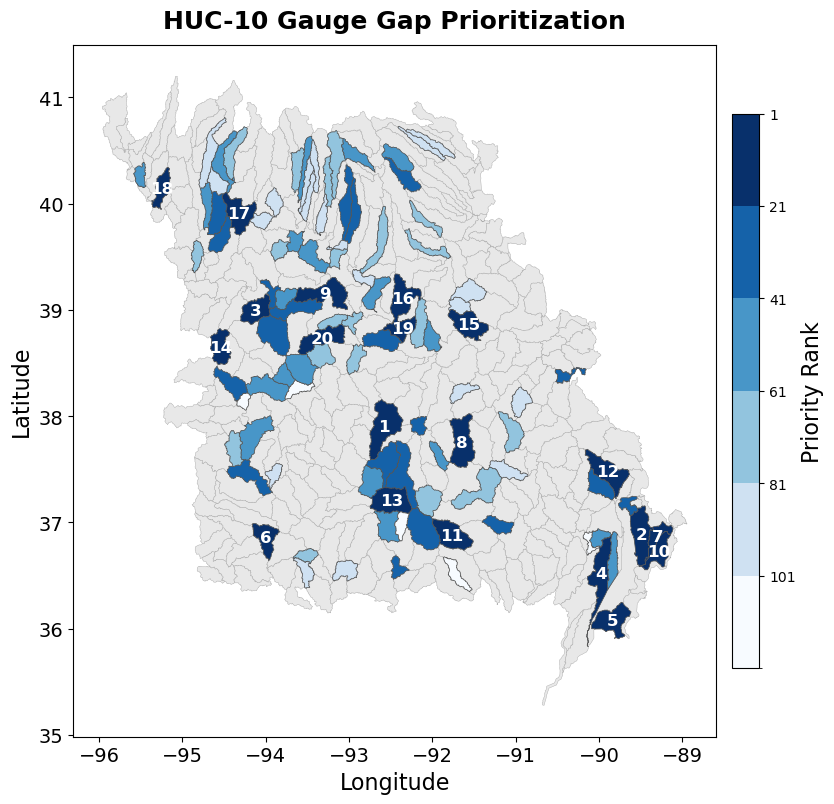

Saved map: prioritization_out\priority_map.png


In [24]:
plot_crs = "EPSG:4326"

huc10_all_plot      = huc10_all.to_crs(plot_crs)
huc10_ungauged_plot = huc10_ungauged.to_crs(plot_crs)

ranked = huc10_ungauged_plot.dropna(subset=["priority_rank"]).copy()
ranked["priority_rank"] = ranked["priority_rank"].astype(int)

n_candidates = len(ranked)
bin_size   = 20                                          
boundaries = list(range(1, n_candidates + bin_size + 1, bin_size))
cmap         = plt.cm.get_cmap("Blues_r", n_candidates)
norm         = BoundaryNorm(boundaries, ncolors=n_candidates)

fig, ax = plt.subplots(figsize=(10, 12))

huc10_all_plot.plot(
    ax=ax,
    color="#e8e8e8",
    edgecolor="#aaaaaa",
    linewidth=0.3,
)

ranked.plot(
    column="priority_rank",
    ax=ax,
    cmap=cmap,
    norm=norm,
    edgecolor="#555555",
    linewidth=0.5,
)

top_n = 20
for _, row in ranked[ranked["priority_rank"] <= top_n].iterrows():
    centroid = row.geometry.centroid
    ax.annotate(
        text=str(int(row["priority_rank"])),
        xy=(centroid.x, centroid.y),
        ha="center", va="center",
        fontsize=12, fontweight="bold",
        color="white",
    )

sm = ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, shrink=0.6, pad=0.02, ticks=boundaries[:-1])
cbar.set_label("Priority Rank", fontsize=16)
cbar.ax.invert_yaxis()

ax.set_title("HUC-10 Gauge Gap Prioritization", fontsize=18, fontweight="bold", pad=12)
ax.set_xlabel("Longitude", fontsize=16)
ax.set_ylabel("Latitude",fontsize=16)
ax.tick_params(labelsize=14)

output_map = OUTPUT_DIR / "priority_map.png"
fig.savefig(output_map, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved map: {output_map}")